# Figure 04 · Noise features · kết quả tự train

14 dataset,4 model,3 mức,168ô/420fit. Tham số công bố chọn bằng validation; đủ original auto seeds.

Notebook này **đọc output thật đã audit rồi tính trung bình/vẽ lại**,không fit model hay chạy HPO.
Đây là accuracy thô của nhóm,không phải đường chuẩn hóa lấy từ paper.
Ba bộ numeric đại diện có thể kiểm tra offline ở `../results/numeric/`.
Xem notebook phân tích kết quả tác giả riêng tại `../../notebooks/`.

In [1]:
from pathlib import Path
import sys, json, io
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'reproduce/results/mechanism_cells.csv').exists())
sys.path.insert(0, str(ROOT / 'reproduce/scripts'))
from plots import cells, plot, means


In [2]:
frame = cells('noise_features')
assert len(frame) == 168
display(frame[['dataset','model','condition','required_seeds','test_accuracy_mean','validation_accuracy_mean']].head(12))

,dataset,model,condition,required_seeds,test_accuracy_mean,validation_accuracy_mean
0,MagicTelescope,ft_transformer,[2.0],"[0, 1, 2]",0.847568,0.845664
1,credit,ft_transformer,[1.5],"[0, 1]",0.769681,0.766882
2,electricity,ft_transformer,[2.0],[0],0.794852,0.790330
3,MagicTelescope,ft_transformer,[1.0],"[0, 1, 2]",0.857651,0.852037
4,pol,ft_transformer,[2.0],"[0, 1, 2]",0.979068,0.973907
5,electricity,ft_transformer,[1.5],[0],0.802729,0.799461
6,credit,ft_transformer,[2.0],"[0, 1]",0.770000,0.770606
7,credit,ft_transformer,[1.0],"[0, 1]",0.774574,0.776564
8,pol,ft_transformer,[1.0],"[0, 1, 2]",0.984105,0.982727
9,pol,ft_transformer,[1.5],"[0, 1, 2]",0.984734,0.979787


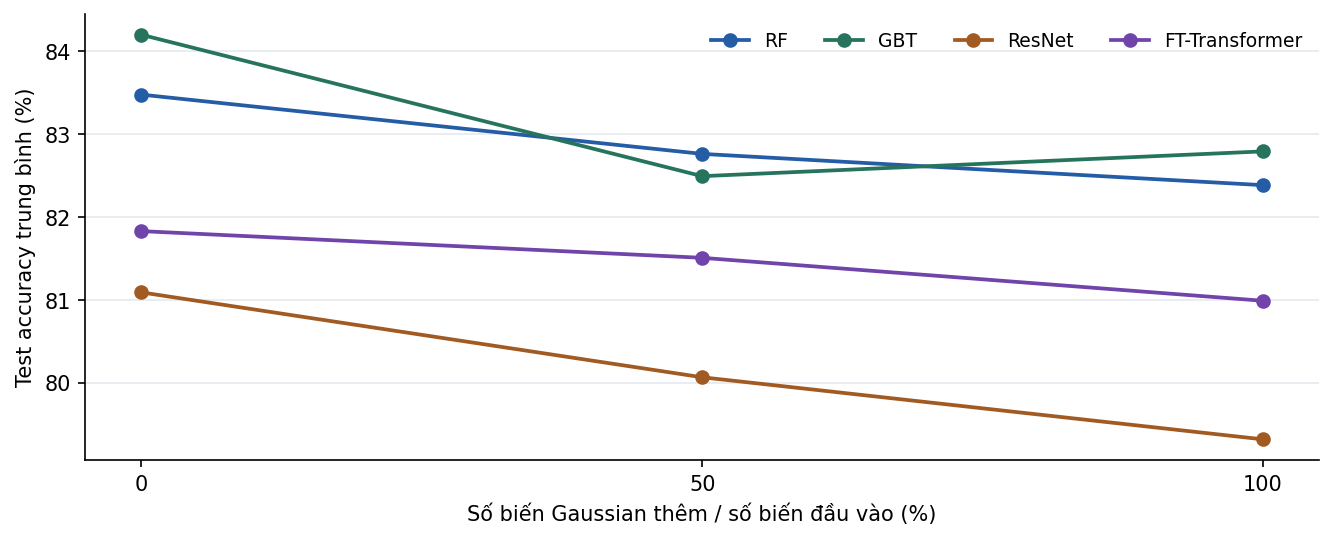

In [3]:
fig = plot('noise_features')
buf = io.BytesIO()
fig.savefig(buf, format='png', dpi=150, bbox_inches='tight')
display(Image(data=buf.getvalue()))

## Một fit gốc đại diện
Nhãn,dự đoán và rowID được lưu;số liệu dưới là một seed,không thay cho toàn bộ grid.

In [4]:
examples = json.loads((ROOT / 'reproduce/results/sample_fits.json').read_bytes())
example = next(e for e in examples if e['id'] == 'noise_features')
display({k: example[k] for k in ['dataset','model','seed','condition','metrics','source_record']})

{'dataset': 'electricity',
 'model': 'rf',
 'seed': 0,
 'condition': [2.0],
 'metrics': {'train': {'accuracy': 0.9962,
   'confusion_matrix': [[4985, 26], [12, 4977]]},
  'validation': {'accuracy': 0.83551861390775,
   'confusion_matrix': [[3533, 742], [663, 3604]]},
  'test': {'accuracy': 0.8386012442303833,
   'confusion_matrix': [[8290, 1661], [1556, 8425]]}},
 'source_record': 13595}

## Nếu muốn train lại
Đọc `../training/README.md` rồi dùng lệnh thủ công với Python3.8. Run All của notebook này luôn chỉ phân tích dữ liệu đã lưu;không gửi job.